In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit

who = [
    "BX_S1",    #: "15 mM LV4",    
    "BXII_S32", #: "15 mM LV4_aSynWT",
    "BXII_S33", #: "15 mM LV4_aSynG14R",
]

/home/riko-hilger/Documents/Physik_GöttingenGrenoble_22to26/8_SoSe_26/SHK_Synaptische_Proteine_Lipidmembranen_SoSe_2026/Code/BM29_data_and_analysis_2026/analysis_BM29_2026/BM29_lib.py:282: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.xlabel("$q$ [nm$\mathrm{^{-1}}]$", fontsize=25)
/home/riko-hilger/Documents/Physik_GöttingenGrenoble_22to26/8_SoSe_26/SHK_Synaptische_Proteine_Lipidmembranen_SoSe_2026/Code/BM29_data_and_analysis_2026/analysis_BM29_2026/BM29_lib.py:537: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
  f"$\chi^2_{{\mathrm{{red}}}} = {red_chi2:.3f}$\n"
/home/riko-hilger/Documents/Physik_GöttingenGrenoble_22to26/8_SoSe_26/SHK_Synaptische_Proteine_Lipidmembranen_SoSe_2026/Code/BM29_data_and_analysis_2026/analysis_BM29_2026/BM29_lib.py:537: SyntaxWarning: "\m" is an invalid

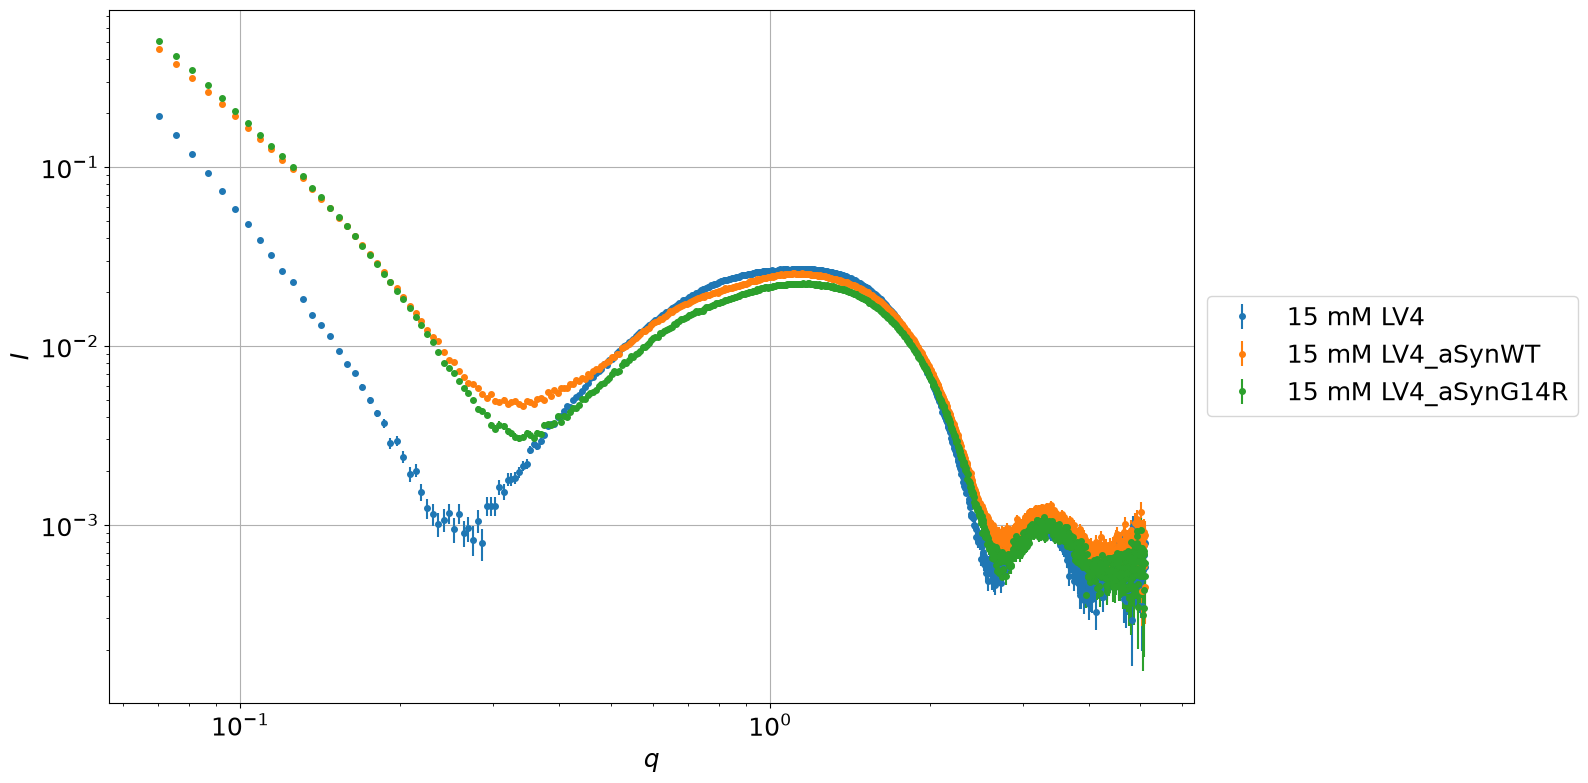

In [13]:
g=BM29.plot_together(who)

[6.641, 4.076, 1.188, 1.476, 0.523, 0.3516, 0.9298, 1.774, 0.0005022, 0.0005267]
R = 12 (0, 28)
sigma_R = 6 (2, 10)
rho_h1 = 1.5 (0, 4)
rho_h2 = 1.5 (0, 4)
sigma_h1 = 0.36 (0.13, 1)
sigma_h2 = 0.36 (0.13, 1)
sigma_c = 0.853 (0.5, 1.2)
z_h = 1.894 (1.5, 2)
scale = 0.000112 (0, 1)
c4 = 0.0007839 (0, 1)
chi2_initial = 4407.8
 
R_fit = 6.6409 ± 0.16647
sigma_R_fit = 4.0759 ± 0.092414
rho_h1_fit = 1.1878 ± 0.29579
rho_h2_fit = 1.4756 ± 0.10773
sigma_h1_fit = 0.523 ± 0.045232
sigma_h2_fit = 0.35162 ± 0.066664
sigma_c_fit = 0.92977 ± 0.31118
z_h_fit = 1.7744 ± 0.05376
scale_fit = 0.00050223 ± 5.8086e-05
c4_fit = 0.00052674 ± 2.1262e-05
chi2 = 176.78


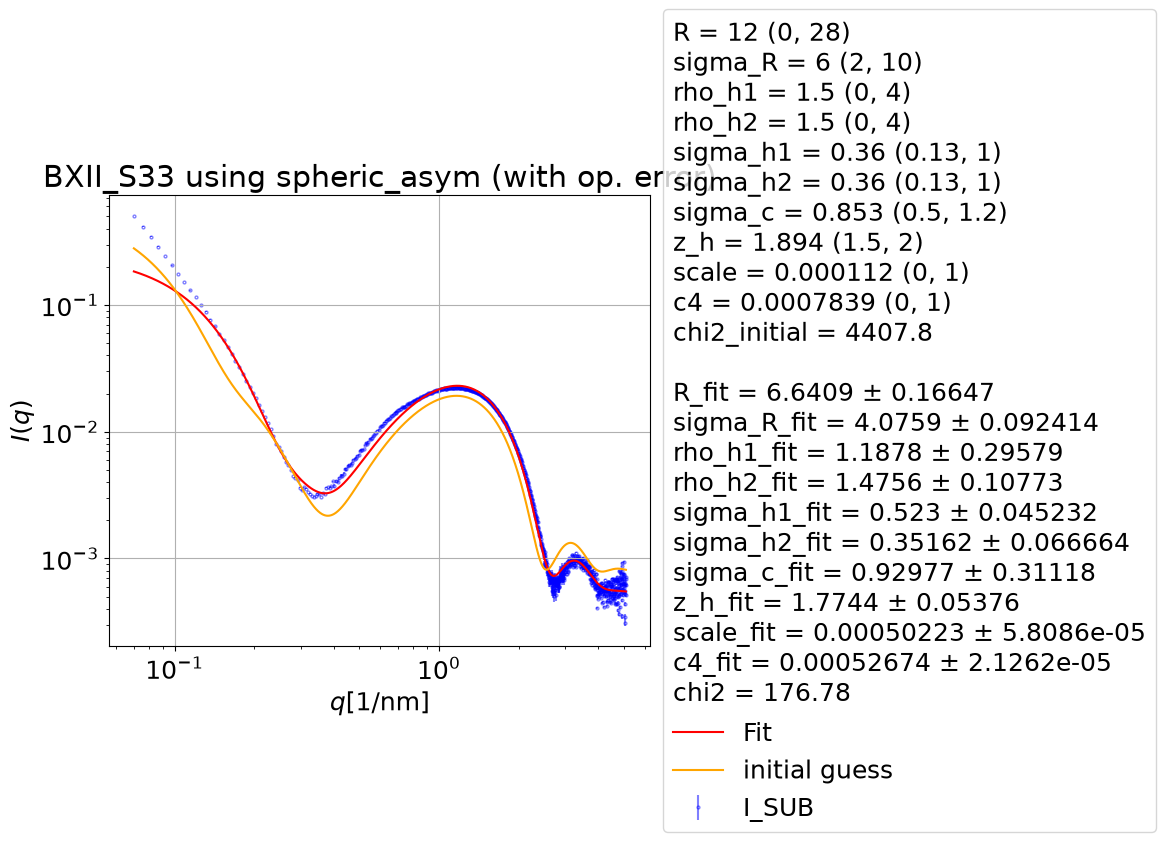

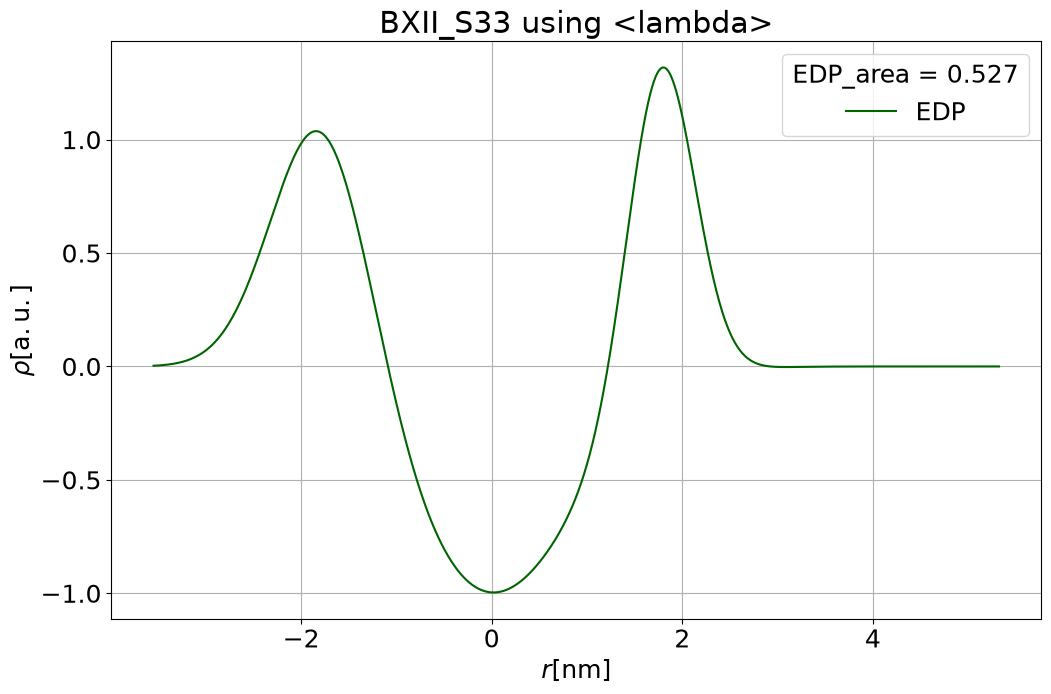

In [15]:
# SPHERIC ASYM + C4
sample = "BXII_S33" 
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
fit_function_name = "ULV_spheric_asym_C4"
mask = (q >= 0.07) & (q <= 5.1)
q    = q[mask]
I    = I[mask]
Ierr_Poisson = Ierr[mask]
I_err_op = BM29.Poisson_error_focus_minimum_highq(q, Ierr_Poisson)

# ========================== Parameters ==========================
R = 18
sigma_R = 7
rho_h1 = 1.8
rho_h2 = 1.4
sigma_h1 = 0.2
sigma_h2 = 0.3
sigma_c = 0.75
z_h = 1.75
scale = 0.00013965
c4 = 0

# ========================== Setting Bounds ==============================
p0           = [   R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,   c4] #,      c2,      c3,      c4]
lower_bounds = [  0,          2,      0.0,      0.0,        0.13,      0.13,      0.5,    1.5,      0,   0] #,       0,       0, -np.inf]
upper_bounds = [  28,         10,      4.0,      4.0,         1.0,       1.0,      1.2,      2,      1,   1] #,       4,     0.5, +np.inf]
p0 =   [12, 6, 1.5, 1.5, 0.36, 0.36, 0.853, 1.894, 0.000112, 0.0007839]

#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err_op, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = ["R_fit", "sigma_R_fit", "rho_h1_fit", "rho_h2_fit", "sigma_h1_fit", "sigma_h2_fit", "sigma_c_fit", "z_h_fit", "scale_fit", "c4_fit"]

perr = np.sqrt(np.diag(pcov))
fit_lib_entry = "["
for name, value in zip(param_names, popt):
    globals()[name] = value
    fit_lib_entry += f"{value:.4g}, "
fit_lib_entry = fit_lib_entry[:-2]
fit_lib_entry += "]"
print(fit_lib_entry)

chi2, info_text_print = fit.all_info(q, I, I_err_op, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
print(info_text_print)

#=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), 10000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err_op, marker="o", markersize=2,markeredgewidth=1,ecolor="Blue", markeredgecolor='Blue', markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{sample} using spheric_asym (with op. error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_op_error2.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()

fig=fit.EDP_plot(R_fit, sigma_h1_fit, sigma_h2_fit, sigma_c_fit, rho_h1_fit, rho_h2_fit, z_h_fit, z_h_fit, info_text_print, 
             f'{sample} using {fit_function.__name__}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error2.png", dpi=400, bbox_inches='tight', pad_inches=0.05)


Computing I(q): 100%|████████████████████████| 909/909 [00:04<00:00, 215.23it/s]


For the sample  BXII_S32_15mM_LV4_aSynWT
chi2 of ULV_spheric_asym_C4:  136.50380492967784 
[12.85, 2.763, 1.6, 0.943, 0.3991, 0.3175, 0.7338, 1.835, 0.0002136, 0.0006917]
chi2 of sph asym lognormal:  397.75698044645134 
[10.02, 0.476, 2.007, 0.995, 0.2618, 0.6, 0.9289, 1.791, 4.504e-07, 0.0006455]
chi2 of TWO prot layers:  63.368727214954774 
[9.001, 0.5105, 1.516, 1.166, 0.24, 0.3912, 0.7002, 1.828, 2.504, 0.857, 0.03437, 4.99, 1.189, 0.04787, 5.587e-07, 0.0006556]


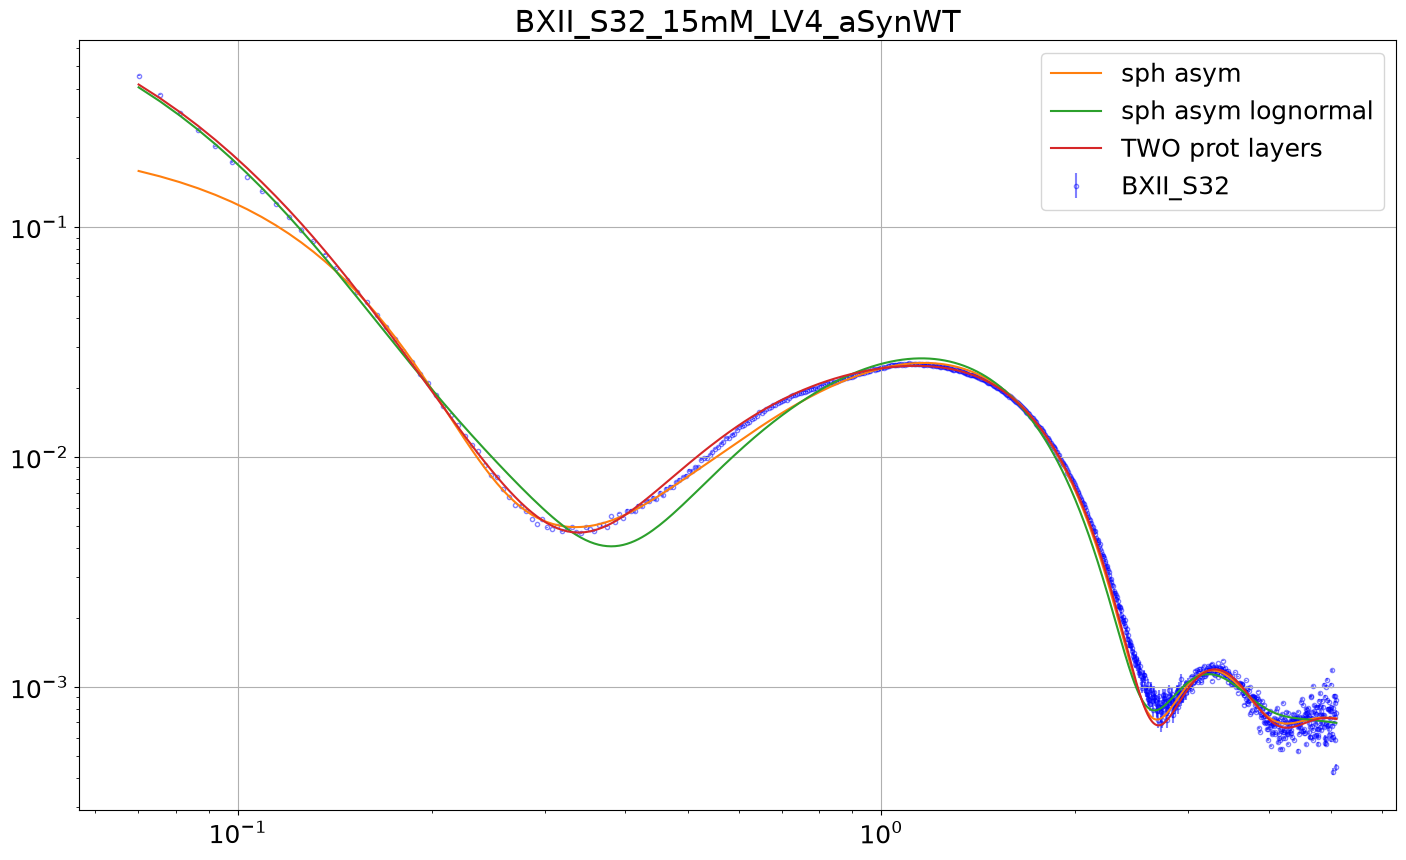

In [6]:
# curves with integrated peptides compare fits
# CALCULATE CHI2
sample = "BXII_S32" 
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

mask = (q >= 0.07) & (q <= 5.1)
q    = q[mask]
I    = I[mask]
Ierr_Poisson = Ierr[mask]
I_err_op = BM29.Poisson_error_focus_minimum_highq(q, Ierr_Poisson)

p0_sph_asym = BM29.best_fits[sample]["ULV_spheric_asym_C4"][1]
# p0_ellips_asym =  BM29.best_fits[sample]["ULV_ellipsoid_asym_C4"][1]
p0_sph_asym_lognormal = BM29.best_fits[sample]["ULV_spheric_asym_C4_lognormal"][1]
p0_TWO_prot_layers = BM29.best_fits[sample]["ULV_lognormal_sph_asym_TWO_prot_layers"][1]

######################################################################
fit_function_name = "ULV_spheric_asym_C4"
fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
I_sph_asym = fit_function(q, *p0_sph_asym)
chi2_sph_asym = BM29.get_chi2(sample, "Poisson_error_focus_minimum_highq", p0_sph_asym, fit_function_name)

# fit_function_name = "ULV_ellipsoid_asym_C4"
# fit_function = lambda q,  R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale, c4: fit.ULV_ellipsoid_asym(q, R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale,   0, 0, c4)
# I_ellips_asym = fit_function(q, *p0_ellips_asym)
# chi2_ellips_asym = BM29.get_chi2(sample, "Poisson_error_focus_minimum_highq", p0_ellips_asym, fit_function_name)

fit_function_name = "ULV_spheric_asym_C4_lognormal"
fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym_lognormal(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
I_sph_asym_lognormal = fit_function(q, *p0_sph_asym_lognormal)
chi2_sph_asym_lognormal = BM29.get_chi2(sample, "Poisson_error_focus_minimum_highq", p0_sph_asym_lognormal,fit_function_name)

fit_function_name = "ULV_lognormal_sph_asym_TWO_prot_layers"
def fit_function(q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, 
                z_out, sigma_out, rho_out, z_in, sigma_in, rho_in, scale, c4):
    return fit.ULV_lognormal_sph_asym_TWO_prot_layers(q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, 
                                                        z_out, sigma_out, rho_out, z_in, sigma_in, rho_in, scale, 0, 0, c4)
I_TWO_prot_layers = fit_function(q, *p0_TWO_prot_layers)
chi2_TWO_prot_layers = BM29.get_chi2(sample, "Poisson_error_focus_minimum_highq", p0_TWO_prot_layers, fit_function_name)

######################################################################
print("For the sample ", BM29.sample_dict[sample])
print("chi2 of ULV_spheric_asym_C4: ", chi2_sph_asym, f"\n{p0_sph_asym}")
# print("chi2 of ellipsoid_asym_C4: ", chi2_ellips_asym)
print("chi2 of sph asym lognormal: ", chi2_sph_asym_lognormal, f"\n{p0_sph_asym_lognormal}")
print("chi2 of TWO prot layers: ", chi2_TWO_prot_layers, f"\n{p0_TWO_prot_layers}")

plt.figure(figsize=(17, 10))
plt.errorbar(q, I, I_err_op, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label=sample, zorder=1)
plt.loglog(q, I_sph_asym, label="sph asym")
# plt.loglog(q, I_ellips_asym, label="ellips asym")
plt.loglog(q, I_sph_asym_lognormal, label="sph asym lognormal")
plt.loglog(q, I_TWO_prot_layers, label="TWO prot layers")
plt.legend()
plt.title(BM29.sample_dict[sample])
plt.grid()

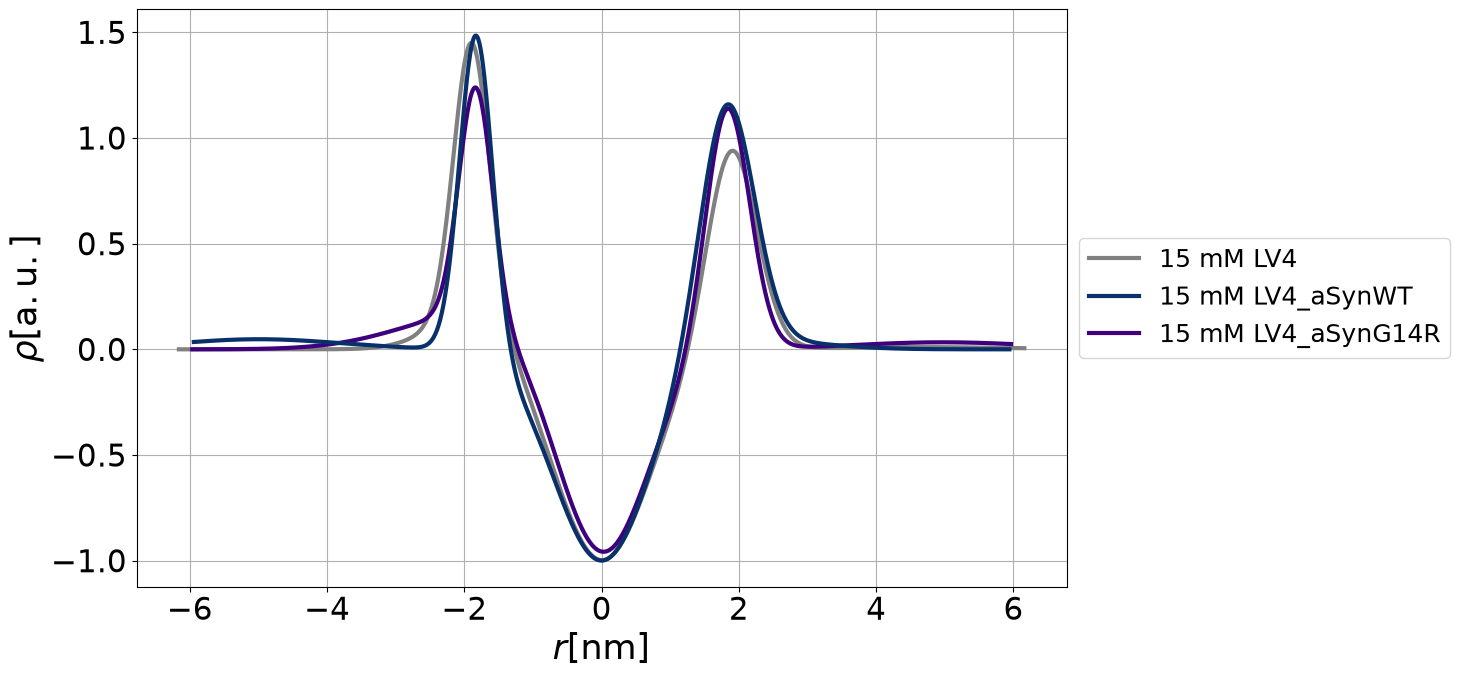

In [3]:
# EDP_plot_together
who = [
    "BX_S1",    #: "15 mM LV4",    
    "BXII_S32", #: "15 mM LV4_aSynWT",
    "BXII_S33", #: "15 mM LV4_aSynG14R",
]
BM29.EDP_plot_together(who, "", fit_function="ULV_lognormal_sph_asym_TWO_prot_layers")

BX_S1 [11.09, 0.444, 1.295, 0.9632, 0.2586, 0.3628, 0.7, 1.895, 4.63, 1.331, 0.01052, 1.8, 0.6138, 0.1828, 4.807e-07, 0.0005004]
BXII_S32 [9.001, 0.5105, 1.516, 1.166, 0.24, 0.3912, 0.7002, 1.828, 2.504, 0.857, 0.03437, 4.99, 1.189, 0.04787, 5.587e-07, 0.0006556]
BXII_S33 [9.002, 0.5535, 1.093, 1.159, 0.2435, 0.32, 0.6677, 1.835, 4.968, 1.318, 0.03332, 1.802, 1.09, 0.169, 5.641e-07, 0.0005387]


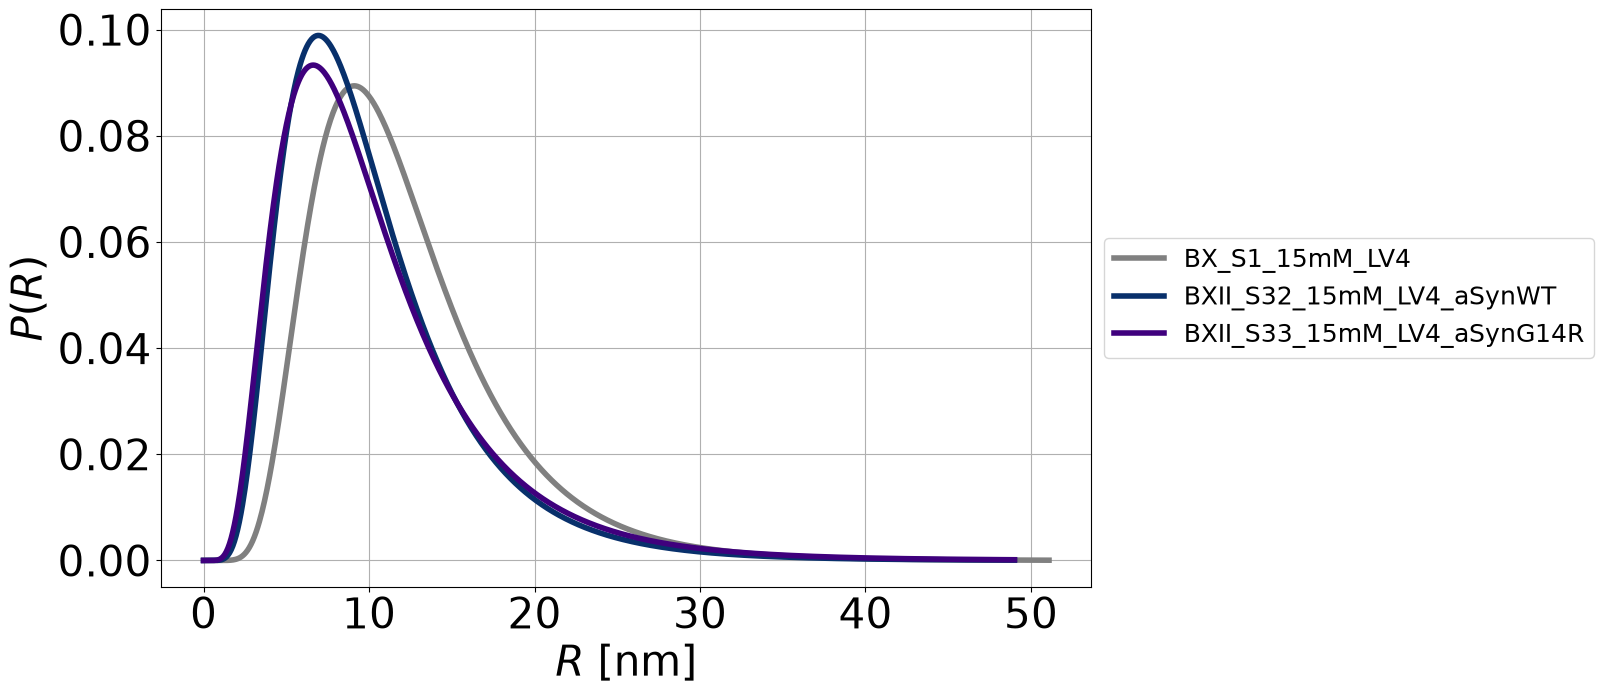

In [4]:
# plot_together_lognorm_polydisp
who = [
    "BX_S1",    #: "15 mM LV4",    
    "BXII_S32", #: "15 mM LV4_aSynWT",
    "BXII_S33", #: "15 mM LV4_aSynG14R",
]
BM29.plot_together_lognorm_polydisp(who, fit_function_name="ULV_lognormal_sph_asym_TWO_prot_layers")
for sample in who:
    print(sample, BM29.best_fits[sample]["ULV_lognormal_sph_asym_TWO_prot_layers"][1])

Computing I(q): 100%|████████████████████████| 909/909 [00:04<00:00, 209.66it/s]


BX_S1 [11.09, 0.444, 1.295, 0.9632, 0.2586, 0.3628, 0.7, 1.895, 4.63, 1.331, 0.01052, 1.8, 0.6138, 0.1828, 4.807e-07, 0.0005004]
BXII_S32 [9.001, 0.5105, 1.516, 1.166, 0.24, 0.3912, 0.7002, 1.828, 2.504, 0.857, 0.03437, 4.99, 1.189, 0.04787, 5.587e-07, 0.0006556]
BXII_S33 [9.002, 0.5535, 1.093, 1.159, 0.2435, 0.32, 0.6677, 1.835, 4.968, 1.318, 0.03332, 1.802, 1.09, 0.169, 5.641e-07, 0.0005387]


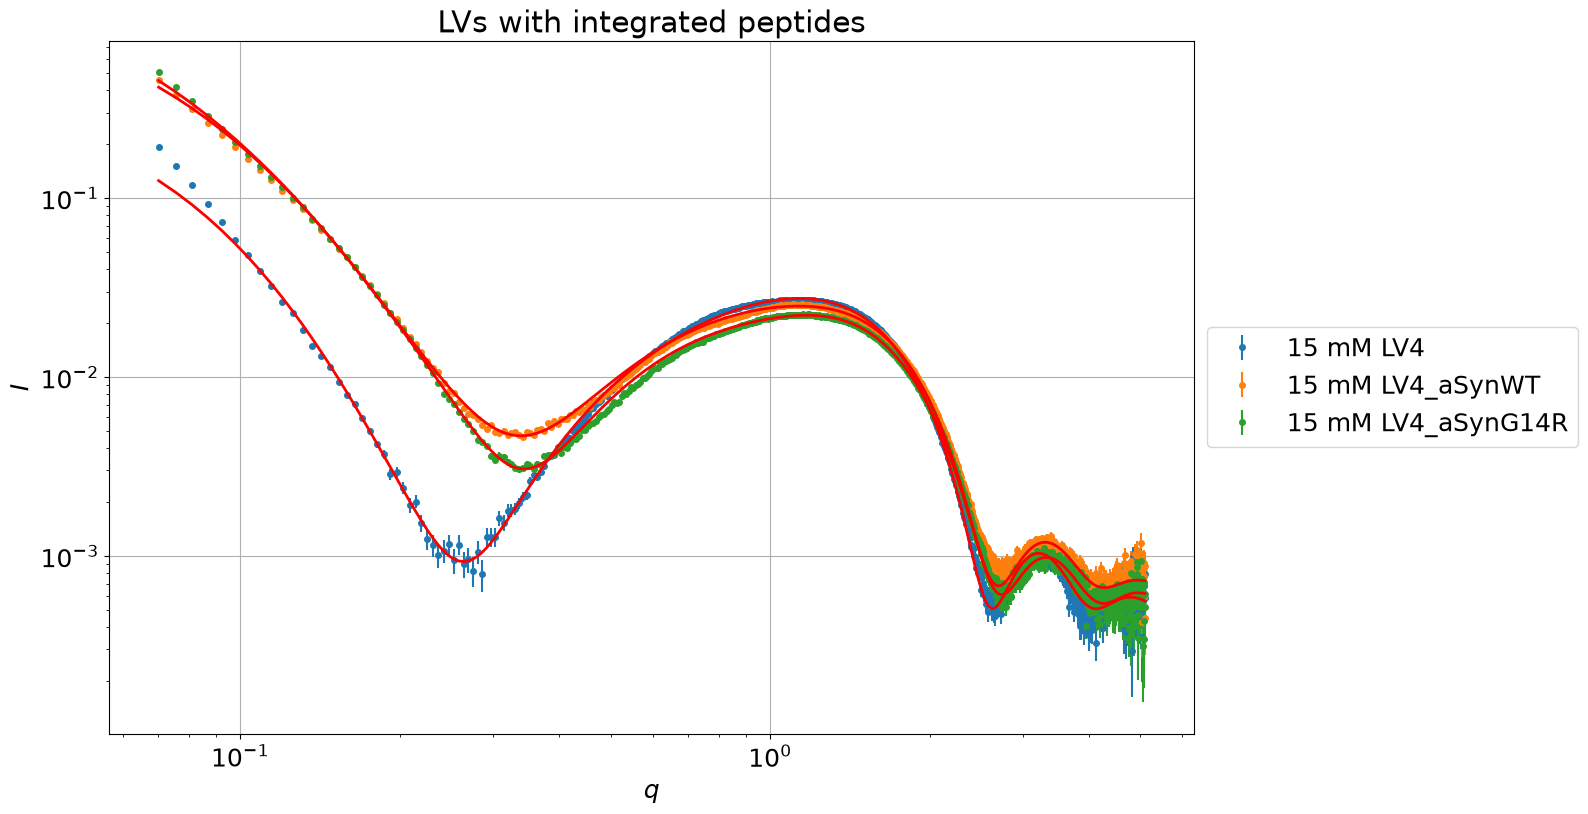

In [5]:
# plot together fit n curves
who = [
    "BX_S1",    #: "15 mM LV4",    
    "BXII_S32", #: "15 mM LV4_aSynWT",
    "BXII_S33", #: "15 mM LV4_aSynG14R",
]
BM29.plot_together(who, "LVs with integrated peptides", fit_function_name="ULV_lognormal_sph_asym_TWO_prot_layers")
for sample in who:
    print(sample, BM29.best_fits[sample]["ULV_lognormal_sph_asym_TWO_prot_layers"][1])